# 🛡️ Smart IDS v3 — Exploratory Data Analysis (EDA)
### Graduation Project | CICIDS2017 Dataset
**Author:** Smart IDS Research Team

This notebook contains only the data loading, cleaning, statistics and visualisation steps extracted from `Smart_IDS_v3.ipynb`.
Dataset and variable names (`df`, `df_clean`, `DATA_PATH`, `SAMPLE_SIZE`, `le`, `CLASS_NAMES`, `NUM_CLASSES`) are unchanged.

---
## 📦 Section 1: Imports & Global Configuration
Only the libraries needed for exploration are imported.

In [ ]:
# ─── Standard Library ─────────────────────────────────────────────────────────
import os
import warnings
warnings.filterwarnings('ignore')

# ─── Numerical & Data ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ─── Visualization ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='darkgrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'

# ─── Label inventory (used for the class mapping in 2.4) ──────────────────────
from sklearn.preprocessing import LabelEncoder

# ─── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ─── Global Config ────────────────────────────────────────────────────────────
# DATA_PATH: Update this to point at your CICIDS2017 CSV files
DATA_PATH   = [
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv"
]
SAMPLE_SIZE = 200_000  # Work with a 200k-row representative subset
                       # (CICIDS2017 full dataset ≈ 2.8M rows — memory constrained)

print(f"✅ Random seed set to : {SEED}")


---
## 🔧 Section 2: Data Loading, Cleaning & Exploration

**Why this matters for CICIDS2017:**  
- The dataset is generated by CICFlowMeter which produces `inf` values in division-by-zero flow stats (e.g. `Flow Bytes/s` when duration = 0).  
- Several minority attack classes have < 1% representation, which is visible in the class distribution below.  
- We sample 200k rows to keep exploration feasible on standard hardware.

In [ ]:
# ─── 2.1  Load Dataset ────────────────────────────────────────────────────────

def load_cicids2017(path_list, sample_size: int = None) -> pd.DataFrame:
    """
    Load CICIDS2017 CSV files. Handles:
      - Merging multiple files if path is a list
      - Leading/trailing whitespace in column names
      - Infinite values and NaN cleaning
      - Optional stratified sampling for memory efficiency
    """
    if isinstance(path_list, list):
        print(f"📂 Loading and merging {len(path_list)} files...")
        # Read all files into a list, stripping column names immediately
        dfs = [pd.read_csv(f, low_memory=False).rename(columns=lambda x: x.strip()) for f in path_list]
        df = pd.concat(dfs, ignore_index=True)
    else:
        print(f"📂 Loading data from: {path_list}")
        df = pd.read_csv(path_list, low_memory=False)
        df.columns = df.columns.str.strip()

    # Standardise the label column name
    label_col = [c for c in df.columns if 'label' in c.lower()]
    if label_col:
        df.rename(columns={label_col[0]: 'Label'}, inplace=True)

    # CRITICAL CLEANING: Handle inf/NaN before sampling or training
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.dropna(inplace=True)

    # Stratified sampling: preserves class distribution in the subset
    if sample_size and len(df) > sample_size:
        # Avoid error if a class has very few samples
        df = df.groupby('Label', group_keys=False).apply(
            lambda x: x.sample(
                min(len(x), max(1, int(sample_size * len(x) / len(df)))),
                random_state=SEED
            )
        ).reset_index(drop=True)

    print(f"✅ Loaded {len(df):,} rows × {df.shape[1]} columns")
    return df


# ── Generate synthetic demo data if the real CSV is not found ─────────────────
# Check if the files exist in the directory
if not all(os.path.exists(f) for f in DATA_PATH):
    print("⚠️  Dataset files not found — generating SYNTHETIC demo data (for testing only).")
    print("    ➡  Set DATA_PATH to your actual CICIDS2017 CSV file paths.")

    N      = SAMPLE_SIZE
    n_feat = 76   # CICIDS2017 has 78 columns total: 76 features + label + others

    # Simulate 8 traffic classes with realistic class imbalance
    class_names = [
        'BENIGN', 'DoS Hulk', 'PortScan', 'DDoS',
        'DoS GoldenEye', 'FTP-Patator', 'SSH-Patator', 'Web Attack'
    ]
    weights = [0.83, 0.06, 0.04, 0.03, 0.01, 0.01, 0.01, 0.01]

    np.random.seed(SEED)
    labels = np.random.choice(class_names, size=N, p=weights)

    feature_names = [
        'Destination Port', 'Flow Duration', 'Total Fwd Packets',
        'Total Backward Packets', 'Total Length of Fwd Packets',
        'Total Length of Bwd Packets', 'Fwd Packet Length Max',
        'Fwd Packet Length Min', 'Fwd Packet Length Mean',
        'Fwd Packet Length Std', 'Bwd Packet Length Max',
        'Bwd Packet Length Min', 'Bwd Packet Length Mean',
        'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
        'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
        'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
        'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
        'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
        'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
        'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
        'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
        'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
        'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count',
        'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count',
        'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size',
        'Avg Fwd Segment Size', 'Avg Bwd Segment Size',
        'Fwd Header Length.1', 'Fwd Avg Bytes/Bulk',
        'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate',
        'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate',
        'Subflow Fwd Packets', 'Subflow Fwd Bytes',
        'Subflow Bwd Packets', 'Subflow Bwd Bytes',
        'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
        'act_data_pkt_fwd', 'min_seg_size_forward',
        'Active Mean', 'Active Std', 'Active Max', 'Active Min',
        'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min'
    ]

    data = np.random.randn(N, len(feature_names)).astype(np.float32)
    inf_idx  = np.random.choice(N * len(feature_names), size=500, replace=False)
    nan_idx  = np.random.choice(N * len(feature_names), size=300, replace=False)
    data.ravel()[inf_idx] = np.inf
    data.ravel()[nan_idx] = np.nan

    df = pd.DataFrame(data, columns=feature_names)
    df['Label'] = labels
    print(f"✅ Synthetic dataset created: {df.shape}")
else:
    # Now this correctly handles the list in DATA_PATH
    df = load_cicids2017(DATA_PATH, sample_size=SAMPLE_SIZE)

print("\n📊 Class Distribution:")
print(df['Label'].value_counts())

📂 Loading and merging 8 files...
✅ Loaded 199,993 rows × 79 columns

📊 Class Distribution:
Label
BENIGN                        160637
DoS Hulk                       16275
PortScan                       11231
DDoS                            9054
DoS GoldenEye                    727
FTP-Patator                      561
SSH-Patator                      417
DoS slowloris                    409
DoS Slowhttptest                 388
Bot                              138
Web Attack � Brute Force         106
Web Attack � XSS                  46
Infiltration                       2
Heartbleed                         1
Web Attack � Sql Injection         1
Name: count, dtype: int64


In [ ]:
# ─── 2.2  Data Cleaning Function ──────────────────────────────────────────────

def clean_cicids_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    """
    Comprehensive cleaning pipeline for CICIDS2017:

    1. Drop non-feature columns (IP addresses — these are identifiers, not features)
    2. Replace ±inf with NaN (numpy can then handle these uniformly)
    3. Drop columns where > 50% values are NaN (likely broken sensors)
    4. Fill remaining NaN with column median (robust to outliers vs. mean)
    5. Clip extreme outliers at ±5σ to prevent gradient explosion in NNs
    6. Drop duplicate rows (CICFlowMeter can produce exact duplicates)
    """
    print("🧹 Starting data cleaning...")
    original_shape = df.shape

    # Step 1: Drop non-informative identifier columns
    id_cols = [c for c in df.columns if any(
        kw in c.lower() for kw in ['ip', 'timestamp', 'flow id', 'src', 'dst']
    )]
    df = df.drop(columns=id_cols, errors='ignore')
    print(f"  Dropped identifier columns: {id_cols}")

    # Separate label before numeric operations
    labels = df['Label'].copy()
    df_feat = df.drop(columns=['Label'])

    # Ensure all feature columns are numeric
    df_feat = df_feat.apply(pd.to_numeric, errors='coerce')

    # Step 2: Replace inf values
    # Why: np.inf breaks StandardScaler and causes NaN loss in neural nets
    inf_count = np.isinf(df_feat.values).sum()
    df_feat.replace([np.inf, -np.inf], np.nan, inplace=True)
    print(f"  Replaced {inf_count:,} inf values with NaN")

    # Step 3: Drop columns with too many NaNs
    nan_threshold = 0.5
    nan_ratio = df_feat.isna().mean()
    cols_to_drop = nan_ratio[nan_ratio > nan_threshold].index.tolist()
    df_feat.drop(columns=cols_to_drop, inplace=True)
    if cols_to_drop:
        print(f"  Dropped {len(cols_to_drop)} columns with >{nan_threshold*100:.0f}% NaN: {cols_to_drop}")

    # Step 4: Fill remaining NaN with column median
    nan_count = df_feat.isna().sum().sum()
    df_feat.fillna(df_feat.median(), inplace=True)
    print(f"  Imputed {nan_count:,} NaN values with column medians")

    # Step 5: Clip outliers at ±5 standard deviations
    # Why: Extreme flow statistics (e.g. 10^12 bytes/sec) are likely meter errors
    #      and will dominate gradients during NN training
    for col in df_feat.columns:
        mu, sigma = df_feat[col].mean(), df_feat[col].std()
        if sigma > 0:
            df_feat[col] = df_feat[col].clip(mu - 5*sigma, mu + 5*sigma)

    # Step 6: Drop duplicates
    df_clean = pd.concat([df_feat, labels], axis=1)
    dup_count = df_clean.duplicated().sum()
    df_clean.drop_duplicates(inplace=True)
    df_clean.reset_index(drop=True, inplace=True)
    print(f"  Removed {dup_count:,} duplicate rows")

    print(f"\n✅ Cleaning complete: {original_shape} → {df_clean.shape}")
    return df_clean


df_clean = clean_cicids_dataframe(df.copy())
print(f"\nFeatures available: {df_clean.shape[1] - 1}")

🧹 Starting data cleaning...
  Dropped identifier columns: []
  Replaced 0 inf values with NaN
  Imputed 0 NaN values with column medians
  Removed 8,667 duplicate rows

✅ Cleaning complete: (199993, 79) → (191326, 79)

Features available: 78


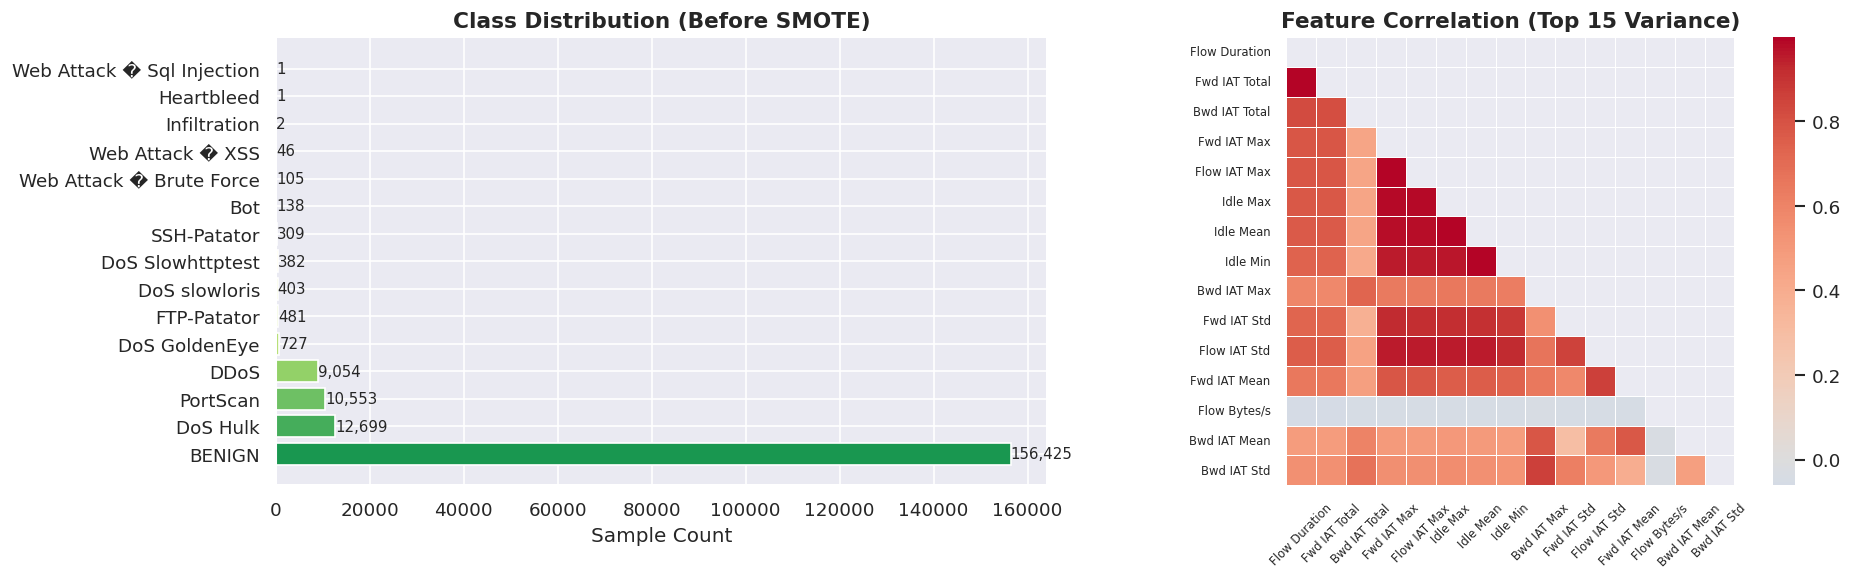

📊 EDA charts saved to eda_overview.png


In [ ]:
# ─── 2.3  Exploratory Visualisation ───────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Class distribution bar chart
class_counts = df_clean['Label'].value_counts()
colors = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(class_counts)))
axes[0].barh(class_counts.index, class_counts.values, color=colors, edgecolor='white')
axes[0].set_title('Class Distribution (Before SMOTE)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sample Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(v + 10, i, f'{v:,}', va='center', fontsize=9)

# Correlation heatmap of top-15 most variable features
top_feat = df_clean.drop(columns=['Label']).std().nlargest(15).index
corr = df_clean[top_feat].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, ax=axes[1], cmap='coolwarm', center=0,
            linewidths=0.5, annot=False, fmt='.1f', square=True,
            xticklabels=[f[-20:] for f in top_feat],
            yticklabels=[f[-20:] for f in top_feat])
axes[1].set_title('Feature Correlation (Top 15 Variance)', fontsize=13, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45, labelsize=7)
axes[1].tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.savefig('eda_overview.png', bbox_inches='tight')
plt.show()
print("📊 EDA charts saved to eda_overview.png")

In [ ]:
# ─── 2.4  Label Encoding ──────────────────────────────────────────────────────

le = LabelEncoder()
y_encoded = le.fit_transform(df_clean['Label'])
NUM_CLASSES = len(le.classes_)
CLASS_NAMES = list(le.classes_)

print(f"Number of classes : {NUM_CLASSES}")
print(f"Class mapping     :")
for i, name in enumerate(CLASS_NAMES):
    print(f"  {i:2d} → {name}")

Number of classes : 15
Class mapping     :
   0 → BENIGN
   1 → Bot
   2 → DDoS
   3 → DoS GoldenEye
   4 → DoS Hulk
   5 → DoS Slowhttptest
   6 → DoS slowloris
   7 → FTP-Patator
   8 → Heartbleed
   9 → Infiltration
  10 → PortScan
  11 → SSH-Patator
  12 → Web Attack � Brute Force
  13 → Web Attack � Sql Injection
  14 → Web Attack � XSS
